# Gráficas del notebook 04 (evaluación final) 

In [1]:
CARPETA_RESULTADOS = "results"

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Valores de la salida de la CV robusta (10x5 = 50 evaluaciones): (media, desviación típica)
res = {
    "XGBoost":             {"AUC-ROC": (0.820, 0.143), "Sensibilidad": (0.633, 0.277), "Especificidad": (0.793, 0.196), "Precisión": (0.683, 0.274), "Exactitud": (0.737, 0.151)},
    "Regresión Logística": {"AUC-ROC": (0.867, 0.136), "Sensibilidad": (0.820, 0.202), "Especificidad": (0.790, 0.190), "Precisión": (0.720, 0.217), "Exactitud": (0.802, 0.153)},
    "Random Forest":       {"AUC-ROC": (0.851, 0.143), "Sensibilidad": (0.607, 0.272), "Especificidad": (0.839, 0.186), "Precisión": (0.715, 0.289), "Exactitud": (0.758, 0.148)},
    "TabPFN":              {"AUC-ROC": (0.873, 0.136), "Sensibilidad": (0.693, 0.265), "Especificidad": (0.825, 0.186), "Precisión": (0.700, 0.283), "Exactitud": (0.779, 0.146)},
}
modelos = list(res)
metricas = ["AUC-ROC", "Sensibilidad", "Especificidad", "Precisión", "Exactitud"]
colores = {"XGBoost": "#0072B2", "Regresión Logística": "#D55E00", "Random Forest": "#009E73", "TabPFN": "#CC79A7"}  # paleta apta para daltonismo

plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

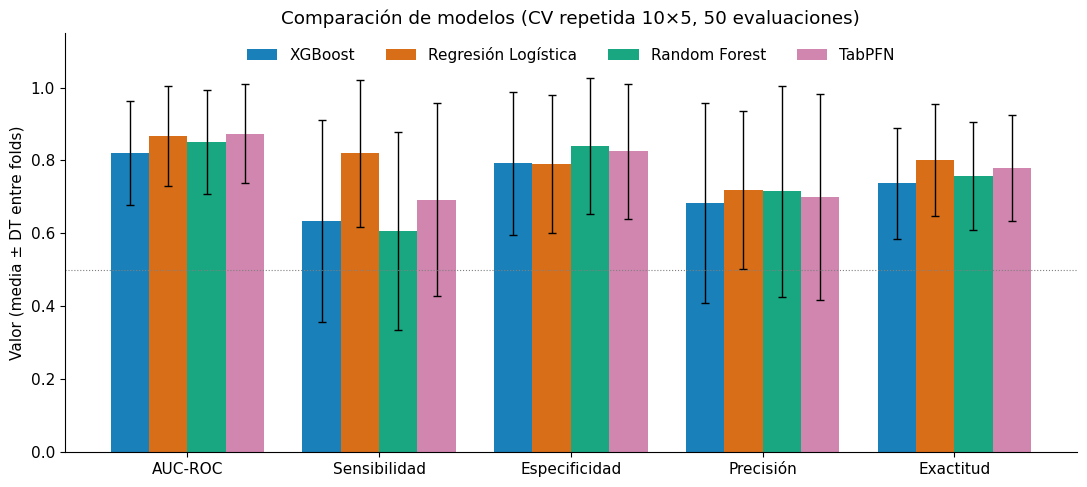

In [3]:
# --- Figura 1: barras agrupadas, todas las métricas ---
fig, ax = plt.subplots(figsize=(11, 5))
ancho = 0.2
x = np.arange(len(metricas))
for i, m in enumerate(modelos):
    medias = [res[m][k][0] for k in metricas]
    sds    = [res[m][k][1] for k in metricas]
    ax.bar(x + (i - 1.5) * ancho, medias, ancho, yerr=sds, capsize=3,
           label=m, color=colores[m], alpha=0.9, error_kw={"elinewidth": 1})
ax.set_xticks(x); ax.set_xticklabels(metricas)
ax.set_ylim(0, 1.15); ax.set_ylabel("Valor (media ± DT entre folds)")
ax.set_title("Comparación de modelos (CV repetida 10×5, 50 evaluaciones)")
ax.axhline(0.5, color="grey", lw=0.8, ls=":")
ax.legend(ncol=4, loc="upper center", frameon=False)
plt.tight_layout()
plt.savefig(f"{CARPETA_RESULTADOS}/fig_comparacion_metricas_barras.png", dpi=300)
plt.show()

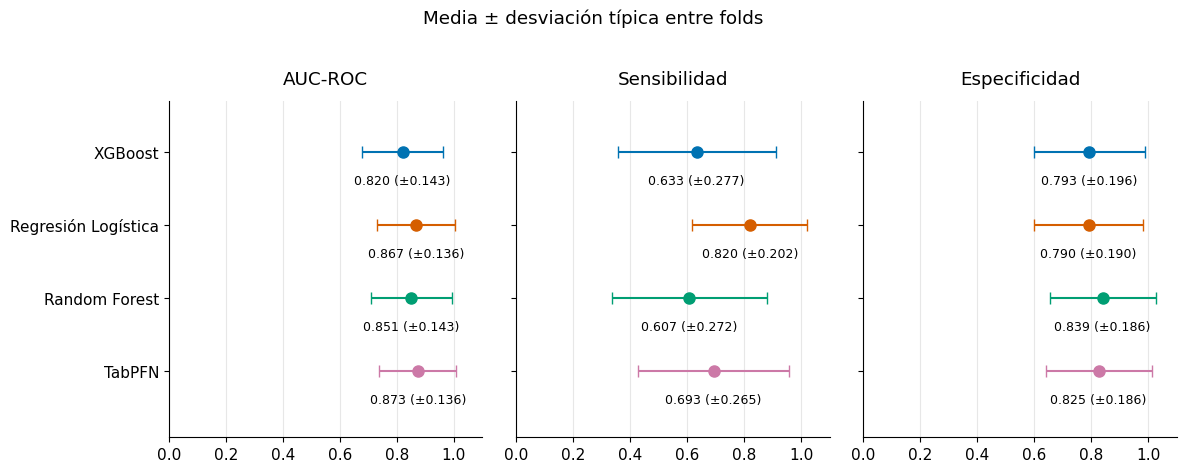

In [4]:
# --- Figura 2: AUC, sensibilidad y especificidad (media ± DT) ---
fig, axes = plt.subplots(1, 3, figsize=(12, 4.6), sharey=True)
for ax, k in zip(axes, ["AUC-ROC", "Sensibilidad", "Especificidad"]):
    for j, m in enumerate(modelos):
        mu, sd = res[m][k]
        ax.errorbar(mu, j, xerr=sd, fmt="o", color=colores[m], capsize=4, markersize=8)
        ax.text(mu, j + 0.30, f"{mu:.3f} (±{sd:.3f})", ha="center", va="top", fontsize=9)
    ax.set_title(k, pad=12); ax.set_xlim(0, 1.1); ax.grid(axis="x", alpha=0.3)
axes[0].set_yticks(range(len(modelos))); axes[0].set_yticklabels(modelos)
axes[0].set_ylim(len(modelos) - 0.1, -0.7)   # invertido y con margen arriba y abajo
fig.suptitle("Media ± desviación típica entre folds", y=1.02)
plt.tight_layout()
plt.savefig(f"{CARPETA_RESULTADOS}/fig_comparacion_auc_sens_esp.png", dpi=300, bbox_inches="tight")
plt.show()

## GRÁFICAS NOTEBOOK 05 (robustez semillas)

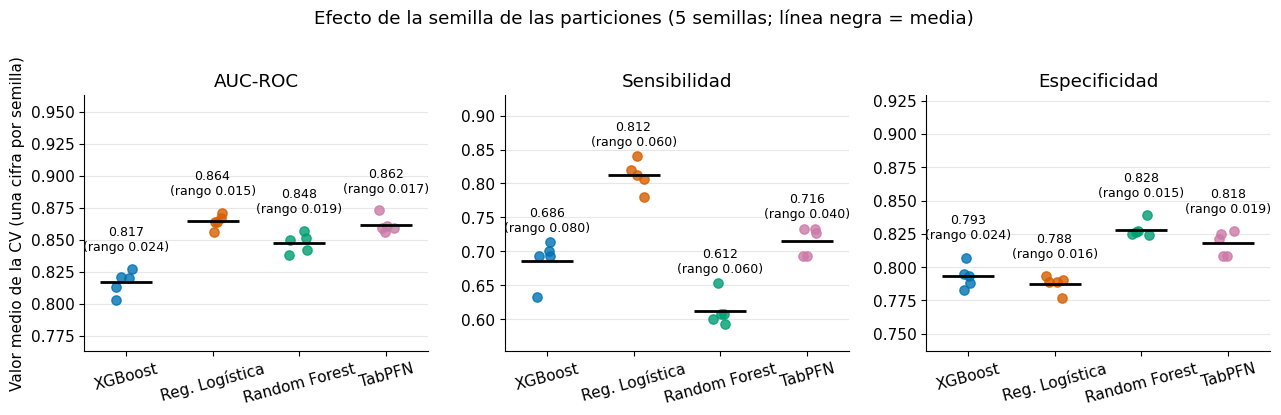

In [5]:
import numpy as np
import matplotlib.pyplot as plt

semillas = [42, 7, 123, 2024, 99]
# [AUC, Sensibilidad, Especificidad] por semilla, en el orden de 'semillas'
datos = {
    "XGBoost":             [(0.820, 0.633, 0.793), (0.821, 0.693, 0.783), (0.803, 0.713, 0.788), (0.813, 0.693, 0.795), (0.827, 0.700, 0.807)],
    "Regresión Logística": [(0.867, 0.820, 0.790), (0.864, 0.780, 0.789), (0.864, 0.807, 0.789), (0.856, 0.840, 0.793), (0.871, 0.813, 0.777)],
    "Random Forest":       [(0.851, 0.607, 0.839), (0.838, 0.653, 0.826), (0.842, 0.600, 0.824), (0.850, 0.593, 0.825), (0.857, 0.607, 0.827)],
    "TabPFN":              [(0.873, 0.693, 0.825), (0.859, 0.693, 0.808), (0.861, 0.733, 0.827), (0.859, 0.727, 0.808), (0.856, 0.733, 0.821)],
}
metricas = ["AUC-ROC", "Sensibilidad", "Especificidad"]
colores = {"XGBoost": "#0072B2", "Regresión Logística": "#D55E00", "Random Forest": "#009E73", "TabPFN": "#CC79A7"}
modelos = list(datos)

plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=False)
rng = np.random.default_rng(0)

for k, (ax, nom) in enumerate(zip(axes, metricas)):
    for j, m in enumerate(modelos):
        v = np.array([f[k] for f in datos[m]])
        jitter = rng.uniform(-0.12, 0.12, len(v))
        ax.scatter(np.full(len(v), j) + jitter, v, color=colores[m], alpha=0.8, s=45, zorder=3)
        ax.hlines(v.mean(), j - 0.3, j + 0.3, color="black", lw=2, zorder=4)
        ax.text(j, v.max() + 0.012, f"{v.mean():.3f}\n(rango {v.max()-v.min():.3f})",
                ha="center", va="bottom", fontsize=9)
    ax.set_xticks(range(len(modelos)))
    ax.set_xticklabels([m.replace("Regresión Logística", "Reg. Logística") for m in modelos], rotation=15)
    ax.set_title(nom); ax.grid(axis="y", alpha=0.3)
    lo = min(f[k] for m in modelos for f in datos[m]); hi = max(f[k] for m in modelos for f in datos[m])
    ax.set_ylim(lo - 0.04, hi + 0.09)

axes[0].set_ylabel("Valor medio de la CV (una cifra por semilla)")
fig.suptitle("Efecto de la semilla de las particiones (5 semillas; línea negra = media)", y=1.03)
plt.tight_layout()
plt.savefig(f"{CARPETA_RESULTADOS}/fig_variabilidad_por_semilla.png", dpi=300, bbox_inches="tight")
plt.show()

### DIAGRAMA DE CAJAS Y BIGOTES 

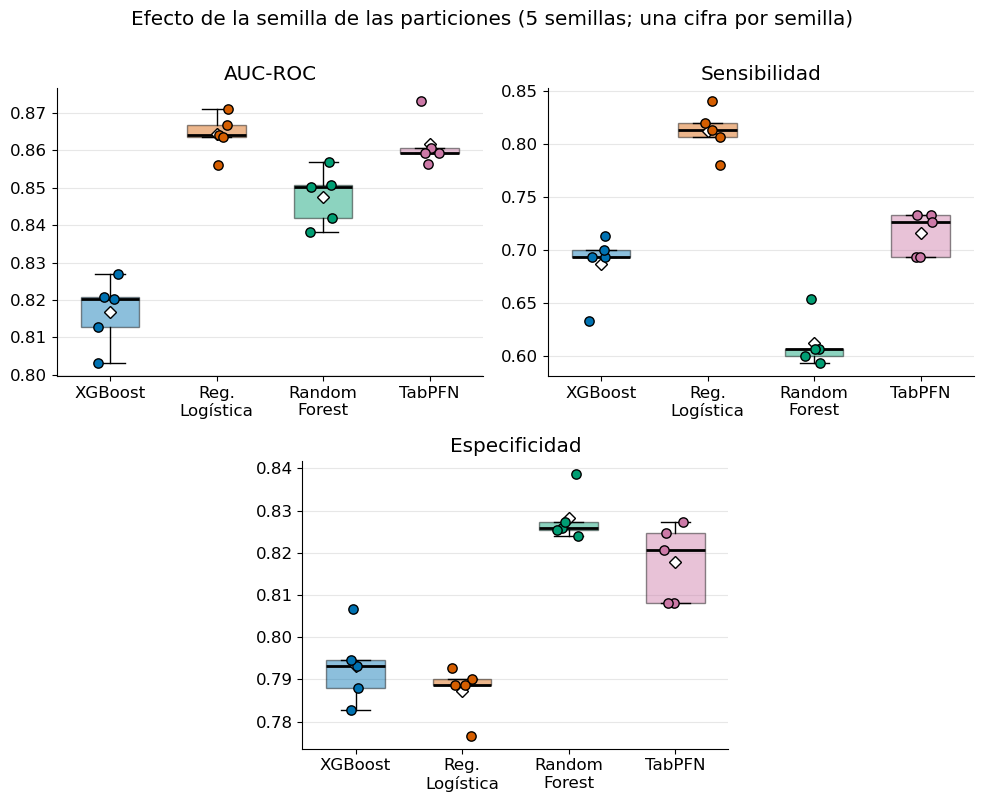

In [15]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

carpeta = globals().get("CARPETA_RESULTADOS", "results")
d = pd.read_csv(f"{carpeta}/robustez_semillas_detalle.csv")

def etiqueta(n):
    n = n.lower()
    if "xgb" in n:    return "XGBoost"
    if "regres" in n: return "Reg. Logística"
    if "forest" in n: return "Random Forest"
    if "tabpfn" in n: return "TabPFN"
    raise ValueError(n)
d["M"] = d["Modelo"].map(etiqueta)

orden = ["XGBoost", "Reg. Logística", "Random Forest", "TabPFN"]
COLORES = {"XGBoost": "#0072B2", "Reg. Logística": "#D55E00",
           "Random Forest": "#009E73", "TabPFN": "#CC79A7"}
paneles = [("AUC_media", "AUC-ROC"),
           ("Sensibilidad_media", "Sensibilidad"),
           ("Especificidad_media", "Especificidad")]

plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False})
fig = plt.figure(figsize=(10, 8))
gs = fig.add_gridspec(2, 4)
axes = [fig.add_subplot(gs[0, 0:2]),   # arriba izquierda
        fig.add_subplot(gs[0, 2:4]),   # arriba derecha
        fig.add_subplot(gs[1, 1:3])]   # abajo, centrado
rng = np.random.default_rng(0)

for ax, (col, titulo) in zip(axes, paneles):
    vals = [d[d["M"] == m][col].values for m in orden]
    bp = ax.boxplot(vals, positions=range(4), widths=0.55, patch_artist=True,
                    showmeans=True, zorder=2,
                    medianprops=dict(color="black", linewidth=2),
                    meanprops=dict(marker="D", markerfacecolor="white",
                                   markeredgecolor="black", markersize=6),
                    flierprops=dict(marker=""))
    for caja, m in zip(bp["boxes"], orden):
        caja.set_facecolor(COLORES[m]); caja.set_alpha(0.45); caja.set_edgecolor("black")
    for j, (m, v) in enumerate(zip(orden, vals)):
        ax.scatter(np.full(len(v), j) + rng.uniform(-0.12, 0.12, len(v)), v,
                   color=COLORES[m], edgecolor="black", s=45, zorder=3)
    ax.set_xticks(range(4)); ax.set_xticklabels([m.replace(" ", "\n") for m in orden])
    ax.set_title(titulo); ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)

fig.suptitle("Efecto de la semilla de las particiones (5 semillas; una cifra por semilla)", y=1.0)
plt.tight_layout()
plt.savefig(f"{carpeta}/fig_boxplot_por_semilla.png", dpi=300, bbox_inches="tight")
plt.show()

## GRÁFICAS NOTEBOOK 6 (Validación cruzada anidada)

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# nombre: (algoritmo, optimizado?, AUC media, AUC DT folds, sens, DT sens (repeticiones), esp, DT esp (repeticiones))
v = {
    "XGBoost":                      ("XGBoost", False, 0.818, 0.152, 0.647, 0.065, 0.778, 0.018),
    "XGBoost (optimizado)":         ("XGBoost", True,  0.848, 0.134, 0.733, 0.021, 0.727, 0.011),
    "Reg. Logística":               ("RL",      False, 0.868, 0.140, 0.780, 0.040, 0.793, 0.030),
    "Reg. Logística (optimizada)":  ("RL",      True,  0.859, 0.144, 0.800, 0.052, 0.775, 0.036),
    "Random Forest":                ("RF",      False, 0.852, 0.136, 0.653, 0.045, 0.822, 0.018),
    "Random Forest (optimizado)":   ("RF",      True,  0.863, 0.133, 0.660, 0.053, 0.811, 0.019),
    "TabPFN":                       ("TabPFN",  False, 0.864, 0.148, 0.693, 0.057, 0.822, 0.014),
}
col = {"XGBoost": "#0072B2", "RL": "#D55E00", "RF": "#009E73", "TabPFN": "#CC79A7"}
REF = "Reg. Logística (optimizada)"   # modelo de referencia para SHAP

plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False})

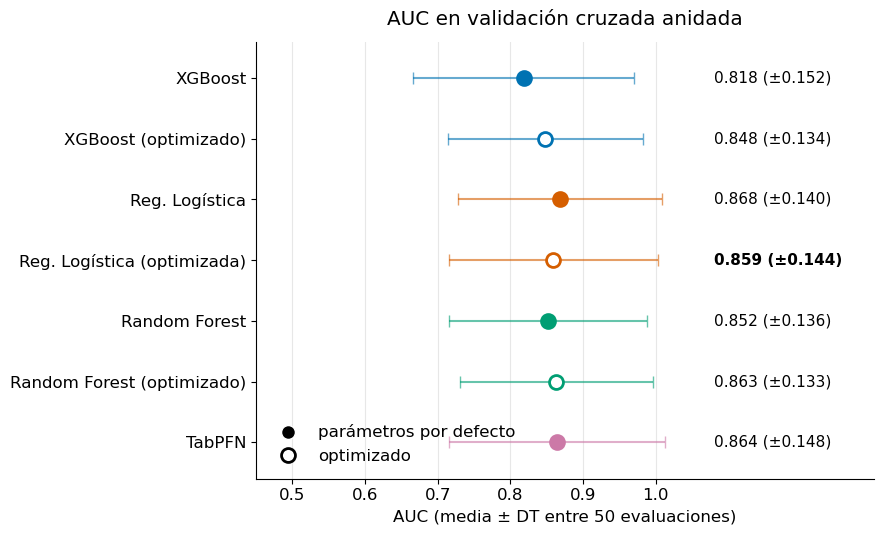

In [7]:
fig, ax = plt.subplots(figsize=(9, 5.5))
nombres = list(v)
for i, n in enumerate(nombres):
    alg, opt, auc, sd, *_ = v[n]
    ax.errorbar(auc, i, xerr=sd, fmt="none", ecolor=col[alg], elinewidth=1.5, capsize=4, alpha=0.6)
    ax.plot(auc, i, "o", color=col[alg], markersize=10, markerfacecolor="white" if opt else col[alg],
            markeredgewidth=2, zorder=3)
    ax.text(1.08, i, f"{auc:.3f} (±{sd:.3f})", va="center", fontsize=11,
            fontweight="bold" if n == REF else "normal")
ax.set_yticks(range(len(nombres))); ax.set_yticklabels(nombres)
ax.set_ylim(len(nombres) - 0.4, -0.6)
ax.set_xlim(0.45, 1.3); ax.set_xticks([0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
ax.grid(axis="x", alpha=0.3)
ax.set_xlabel("AUC (media ± DT entre 50 evaluaciones)")
ax.set_title("AUC en validación cruzada anidada", pad=12)

leg = [Line2D([0], [0], marker="o", color="w", markerfacecolor="k", markersize=10, label="parámetros por defecto"),
       Line2D([0], [0], marker="o", color="w", markerfacecolor="w", markeredgecolor="k", markeredgewidth=2, markersize=10, label="optimizado")]
ax.legend(handles=leg, loc="lower left", frameon=False)
plt.tight_layout()
plt.savefig(f"{CARPETA_RESULTADOS}/fig_cv_anidada_auc.png", dpi=300, bbox_inches="tight")
plt.show()

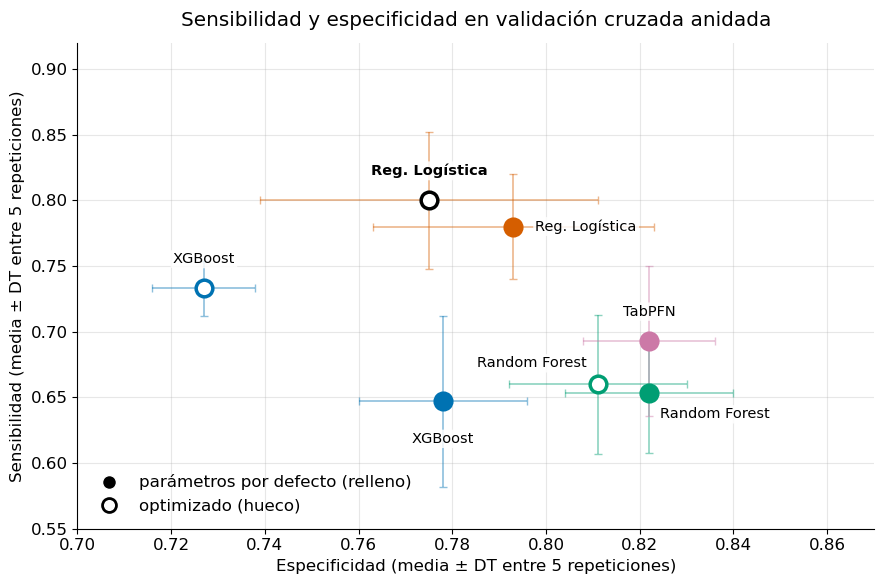

In [10]:
# desplazamiento (puntos) y alineación de la etiqueta de cada modelo
# etiqueta corta y posición (desplazamiento en puntos, alineación) de cada modelo
nombre_corto = {
    "XGBoost": "XGBoost", "XGBoost (optimizado)": "XGBoost",
    "Reg. Logística": "Reg. Logística", "Reg. Logística (optimizada)": "Reg. Logística",
    "Random Forest": "Random Forest", "Random Forest (optimizado)": "Random Forest",
    "TabPFN": "TabPFN",
}
pos = {
    "XGBoost":                     ((0, -22),  "center", "top"),
    "XGBoost (optimizado)":        ((0, 16),   "center", "bottom"),
    "Reg. Logística":              ((16, 0),   "left",   "center"),
    "Reg. Logística (optimizada)": ((0, 16),   "center", "bottom"),
    "Random Forest":               ((8, -10),  "left",  "top"),      # pegada, abajo a la derecha
    "Random Forest (optimizado)":  ((-8, 10),  "right", "bottom"),   # pegada, arriba a la izquierda
    "TabPFN":                      ((0, 16),   "center", "bottom"),
}

fig, ax = plt.subplots(figsize=(9, 6))
for n, (alg, opt, auc, sd, se, sdse, es, sdes) in v.items():
    ax.errorbar(es, se, xerr=sdes, yerr=sdse, fmt="none", ecolor=col[alg], elinewidth=1.2, capsize=3, alpha=0.45, zorder=2)
    ax.plot(es, se, "o", color=col[alg], markersize=12, markerfacecolor="white" if opt else col[alg],
            markeredgewidth=2.5, markeredgecolor="black" if n == REF else col[alg], zorder=4)
    (dx, dy), ha, va = pos[n]
    etiqueta = nombre_corto[n] 
    ax.annotate(etiqueta, (es, se), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va, fontsize=10.5,
                fontweight="bold" if n == REF else "normal",
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85), zorder=5)
ax.set_xlim(0.70, 0.87); ax.set_ylim(0.55, 0.92); ax.grid(alpha=0.3)
ax.set_xlabel("Especificidad (media ± DT entre 5 repeticiones)")
ax.set_ylabel("Sensibilidad (media ± DT entre 5 repeticiones)")
ax.set_title("Sensibilidad y especificidad en validación cruzada anidada", pad=12)

leg = [Line2D([0], [0], marker="o", color="w", markerfacecolor="k", markersize=10, label="parámetros por defecto (relleno)"),
       Line2D([0], [0], marker="o", color="w", markerfacecolor="w", markeredgecolor="k", markeredgewidth=2, markersize=10, label="optimizado (hueco)")]
ax.legend(handles=leg, loc="lower left", frameon=False)
plt.tight_layout()
plt.savefig(f"{CARPETA_RESULTADOS}/fig_cv_anidada_sens_esp.png", dpi=300, bbox_inches="tight")
plt.show()

PermutationExplainer explainer: 86it [00:17,  4.91it/s]                                                                


HER2 (presence)_positive                                      0.1646
Systemic therapy breast response (RECIST)_partial response    0.0800
Delta SUV max                                                 0.0431
dtype: float64


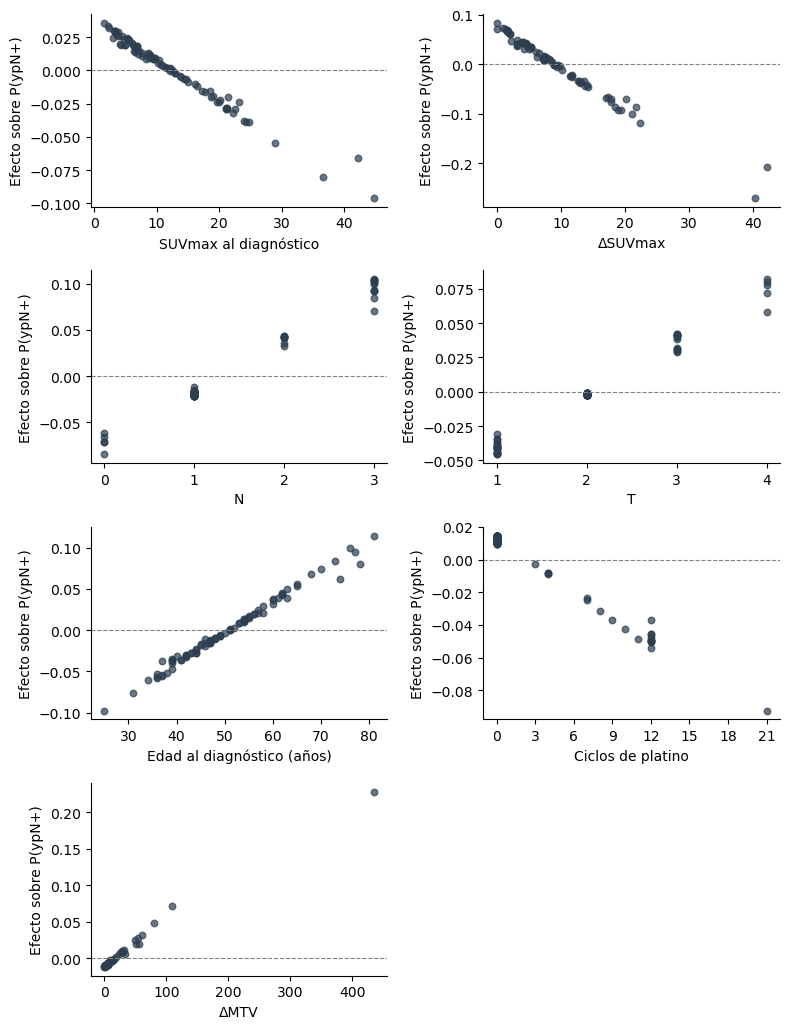

In [12]:
import numpy as np
import pandas as pd
import joblib
import shap
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

CARPETA_RESULTADOS = "results"
CARPETA_FIGURAS = "fig"
SEMILLA = 42

# 1. Cargar datos y modelo de referencia ya guardados
X = pd.read_csv(f"{CARPETA_RESULTADOS}/X_full.csv")
paquete = joblib.load(f"{CARPETA_RESULTADOS}/modelo_referencia.pkl")
pipeline_final = paquete['pipeline']
variables_finales = paquete['variables']

# 2. Recalcular SHAP (igual que las celdas 91 y 95)
datos = pd.DataFrame(pipeline_final.named_steps['imputer'].transform(X[variables_finales]),
                     columns=variables_finales)
modelo = pipeline_final.named_steps['modelo']
explainer = shap.Explainer(lambda d: modelo.predict_proba(d)[:, 1], datos, seed=SEMILLA)
shap_values = explainer(datos).values
nombres = list(datos.columns)
sv = pd.DataFrame(shap_values, columns=nombres)

# Comprobación: debe salir HER2 (presence)_positive = 0.1646
print(pd.Series(np.abs(shap_values).mean(axis=0), index=nombres).sort_values(ascending=False).round(4).head(3))

# 3. Variables continuas (las que no son 0/1)
es_bin = lambda v: set(datos[v].dropna().unique()) <= {0, 1}
binarias = [v for v in nombres if es_bin(v)]
cont = [v for v in nombres if v not in binarias]

nombres_es = {
    "SUV max (at diagnosis)": "SUVmax al diagnóstico",
    "Delta SUV max": "ΔSUVmax",
    "Delta MTV": "ΔMTV",
    "Age at diagnosis": "Edad al diagnóstico (años)",
    "ciclos_platino": "Ciclos de platino",
    "N": "N",
    "T": "T",
}

n = len(cont); cols = 2; filas_ = int(np.ceil(n/cols))
plt.rcParams.update({'font.size': 10})
fig, axs = plt.subplots(filas_, cols, figsize=(8, 2.6*filas_))
for ax, v in zip(np.ravel(axs), cont):
    ax.scatter(datos[v], sv[v], s=22, alpha=.7, color='#2c3e50')
    ax.axhline(0, ls='--', lw=.8, color='gray')
    ax.set_xlabel(nombres_es.get(v, v))
    ax.set_ylabel("Efecto sobre P(ypN+)")
    if v in ("N", "T", "ciclos_platino"):
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
for ax in np.ravel(axs)[n:]:
    ax.axis('off')
plt.tight_layout()
plt.savefig(f"{CARPETA_FIGURAS}/shap_continuas.png", dpi=300, bbox_inches='tight')
plt.show()
plt.rcdefaults()